In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Ορισμός παραμέτρων
theta_o = 2
N = 30
datasets_count = 50
std_dev = 8   # Αφού η διακύμανση είναι 64

datasets = []
ls_estimates = []

# Δημιουργία δεδομένων και υπολογισμός LS
for _ in range(datasets_count):
    x = np.random.randn(N) 
    noise = np.random.normal(0, std_dev, N)
    y = theta_o * x + noise
    
    datasets.append((x, y))
    
    # Υπολογισμός Ελαχίστων Τετραγώνων (LS): θ = sum(x*y) / sum(x^2)
    theta_ls = np.sum(x * y) / np.sum(x**2)
    ls_estimates.append(theta_ls)

# Υπολογισμός συνολικού MSE για τον LS εκτιμητή
ls_estimates = np.array(ls_estimates)
mse_ls = np.mean((ls_estimates - theta_o)**2)
print(f"MSE of LS estimator: {mse_ls:.4f}")

MSE of LS estimator: 2.2997


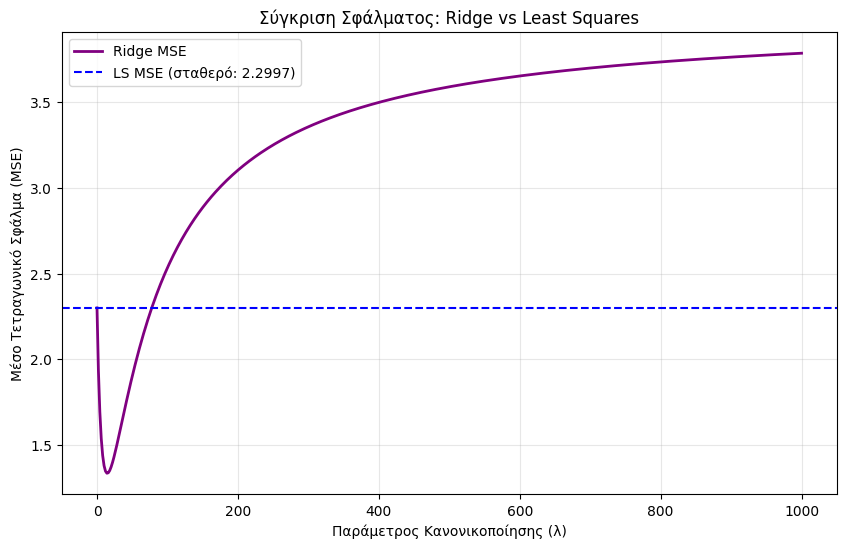

In [2]:
# Δοκιμή διάφορων τιμών για το λ (Ridge Regression)
lambdas = np.linspace(0, 1000, 500)
mse_ridge_list = []

for lam in lambdas:
    ridge_estimates = []
    for x, y in datasets:
        # Υπολογισμός Ridge: θ = sum(x*y) / (sum(x^2) + λ)
        theta_ridge = np.sum(x * y) / (np.sum(x**2) + lam)
        ridge_estimates.append(theta_ridge)
    
    # Υπολογισμός MSE για το συγκεκριμένο λ
    mse_ridge = np.mean((np.array(ridge_estimates) - theta_o)**2)
    mse_ridge_list.append(mse_ridge)

# Γραφική απεικόνιση
plt.figure(figsize=(10, 6))
plt.plot(lambdas, mse_ridge_list, label='Ridge MSE', color='purple', linewidth=2)
plt.axhline(y=mse_ls, color='blue', linestyle='--', label=f'LS MSE (σταθερό: {mse_ls:.4f})')
plt.xlabel('Παράμετρος Κανονικοποίησης (λ)')
plt.ylabel('Μέσο Τετραγωνικό Σφάλμα (MSE)')
plt.title('Σύγκριση Σφάλματος: Ridge vs Least Squares')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()